# Data Analysis | Correlates of War

# Introduction
In this notebook, we will perform a data analysis on our dataset. Let us remember our question:

- Is the distance between city capitals and Moscow, the capital of Russia, a value correlated with **higher defense expenditures**, measured as % of GDP?

## Motivation
Given our problem, we can do a **comparative** analysis and uncover possible **correlations** between **% GDP expenditures on defense** and **distance between European capitals and Moscow** (capital of Russia).

## Expected outcomes
After working through this problem, we want to:
- Define our `y` and `x` variables and identify them in the data.
- Use this study case to understand concepts of conditional probability, conditional distribution, and conditional mean.
- Create informative visualizations to understand conditional means, other conditional statistics, and joint distributions of quantitative variables.
- Understand the concepts of dependence, mean-dependence, and correlation, and produce and interpret correlation coefficients.

# Set up libraries and working environment, import dataset


In [1]:
# Import required libraries
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as mticker
from plotnine import *
from mizani.formatters import percent_format
import numpy as np

In [2]:
# Create directory folders to store our data
dirname = os.getcwd()

raw_data = f"{dirname}/data/raw/"
transformed_data = f"{dirname}/data/transformed/"
refined_data = f"{dirname}/data/refined/"

paths = [raw_data, transformed_data, refined_data]

for path in paths:
    if not os.path.exists(path):
        os.makedirs(path)
    

In [3]:
# Import data
eur_military_expenditures = pd.read_csv(f"{transformed_data}military_expenditures_final.csv")

In [4]:
eur_military_expenditures.shape

(1408, 13)

In [5]:
eur_military_expenditures.head()

,country,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,capital_city,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi
0,Albania,1993,1.772197e+08,3.928984e+07,0.031995,NaN,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987
1,Albania,1994,1.694002e+08,4.964950e+07,0.025478,NaN,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987
2,Albania,1995,1.578554e+08,5.090752e+07,0.020536,NaN,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987
3,Albania,1996,1.417564e+08,4.571336e+07,0.013790,NaN,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987
4,Albania,1997,9.897513e+07,2.982549e+07,0.012831,0.044247,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987


In [6]:
eur_military_expenditures.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1408 entries, 0 to 1407
Data columns (total 13 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   country                            1408 non-null   object 
 1   year                               1408 non-null   int64  
 2   military_expenditures_usd_2022     1362 non-null   float64
 3   military_expenditures_current_usd  1362 non-null   float64
 4   share_GDP                          1330 non-null   float64
 5   share_govt                         1229 non-null   float64
 6   capital_city                       1408 non-null   object 
 7   latitude                           1408 non-null   float64
 8   longitude                          1408 non-null   float64
 9   moscow_lat                         1408 non-null   float64
 10  moscow_long                        1408 non-null   float64
 11  distance_km                        1408 non-null   float

## Sample selection
Let's work with the latest year of data.

In [38]:
eur_military_expenditures_2024 = eur_military_expenditures.loc[
    lambda x: (eur_military_expenditures["year"] == 2024)
]

In [39]:
eur_military_expenditures_2024.describe()

,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi
count,44.0,4.400000e+01,4.400000e+01,43.000000,42.000000,44.000000,44.000000,4.400000e+01,4.400000e+01,44.000000,44.000000
mean,2024.0,1.592914e+10,1.628715e+10,0.029324,0.075752,48.243806,17.583793,5.575500e+01,3.762180e+01,1825.976727,1134.609336
std,0.0,2.984998e+10,3.007040e+10,0.050958,0.108581,6.950434,14.066383,1.437515e-14,7.187574e-15,757.181172,470.490568
min,2024.0,0.000000e+00,0.000000e+00,0.002391,0.009984,35.899700,-21.895400,5.575500e+01,3.762180e+01,0.000000,0.000000
25%,2024.0,1.213380e+09,1.235854e+09,0.015044,0.032886,42.330825,12.047350,5.575500e+01,3.762180e+01,1549.842711,963.027613
50%,2024.0,4.111008e+09,4.209353e+09,0.020108,0.043866,47.823100,18.698150,5.575500e+01,3.762180e+01,1799.813883,1118.352499
75%,2024.0,1.064376e+10,1.083656e+10,0.023580,0.064532,52.726575,24.800175,5.575500e+01,3.762180e+01,2219.446176,1379.099917
max,2024.0,1.505340e+11,1.489673e+11,0.344815,0.540069,64.135500,49.892000,5.575500e+01,3.762180e+01,3915.117069,2432.740961


# Visualize the distribution of `share_GDP`
Let's take a look at the distribution of `share_GDP`.

In [40]:
eur_military_expenditures_2024.loc[:, ["share_GDP"]].describe()

,share_GDP
count,43.000000
mean,0.029324
std,0.050958
min,0.002391
25%,0.015044
50%,0.020108
75%,0.023580
max,0.344815


We can say a few things about it:
- The average expenditure as a percentage of GDP is 2.9%.
- The standard deviation is quite high (5%), so we can expect some skewness.
- The median is 2%, which confirms the previous assumption.
- The highest value is an astonishing 34%, which is probably due to Ukraine.

We should remove Ukraine and Russia from this dataset, as it will influence our data and we are interested on the other countries that are not in war with Russia.


In [41]:
eur_df_2024 = eur_military_expenditures_2024.loc[
    (~eur_military_expenditures_2024["country"].isin(["Ukraine", "Russia"]) )
].copy().reset_index(drop=True)

Let's profile our data once again.

In [43]:
eur_df_2024.loc[:, ["share_GDP"]].describe()

,share_GDP
count,41.000000
mean,0.020624
std,0.010869
min,0.002391
25%,0.014766
50%,0.019977
75%,0.022982
max,0.054817


Aha! As we can see, our values changed quite a bit.
- The mean value is `2.0%`, while the standard deviation is "just" `1.0%`.
- Our median value is `1.9`%, which suggests some skewness.

Let's visualize this distribution.

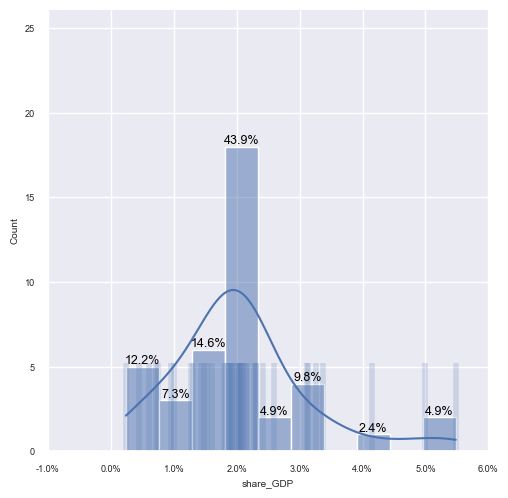

In [44]:
sns.set_style("darkgrid")
sns.set_theme(font_scale=0.6)
ax = sns.displot(
    data=eur_df_2024["share_GDP"], 
    binwidth=0.005,
    kde=True, 
    rug=True,
    rug_kws={"alpha": 0.2, "linewidth": 4, "height": 0.2})
ax.set_xticklabels(ha="center")
for x in ax.axes.flat:
    x.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x*100:.1f}%"))
    total = sum(p.get_height() for p in x.patches)
    # Annotate bars
    for patch in x.patches:
        height = patch.get_height()
        if height > 0:
            percent = 100 * height / total
            x.annotate(
                f"{percent:.1f}%",
                (patch.get_x() + patch.get_width() / 2, height),
                ha="center", va="bottom", fontsize=9, color="black"
            )

plt.show()

As we can see, most countries allocate between 1.5 and 2.0% of their GDP to the military sector. This is, by far, our **mode**.

Let us now check the distribution of the distance from Moscow.

In [45]:
eur_df_2024.loc[:, ["distance_km"]].describe()

,distance_km
count,42.000000
mean,1894.884284
std,698.052361
min,677.698516
25%,1583.152705
50%,1838.038864
75%,2229.427848
max,3915.117069


Let's take a look at the summary statistics:
- The average distance is 1850km.
- The standard deviation is 747km.
- The median is 1805, which hints at a more normal distribution.
- The highest value is 3915km.

Let's visualize the data.


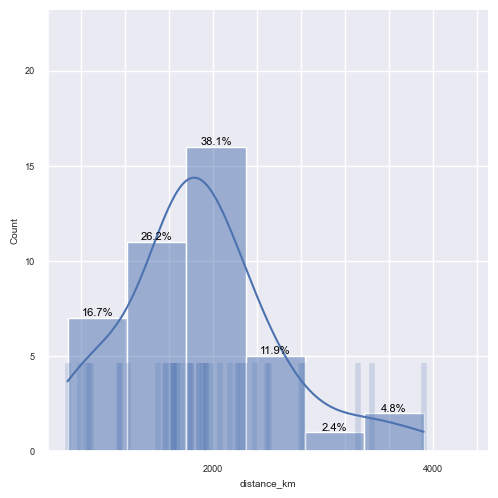

In [47]:
sns.set_style("darkgrid")
sns.set_theme(font_scale=0.6)
ax = sns.displot(
    data=eur_df_2024["distance_km"], 
    binwidth=500,
    kde=True, 
    rug=True,
    rug_kws={"alpha": 0.2, "linewidth": 4, "height": 0.2})
ax.set_xticklabels(ha="center")
for x in ax.axes.flat:
    # Set number of ticks
    x.xaxis.set_major_locator(mticker.MaxNLocator())
    total = sum(p.get_height() for p in x.patches)
    # Annotate bars
    for patch in x.patches:
        height = patch.get_height()
        if height > 0:
            percent = 100 * height / total
            x.annotate(
                f"{percent:.1f}%",
                (patch.get_x() + patch.get_width() / 2, height),
                ha="center", va="bottom", fontsize=8, color="black"
            )

plt.show()

As we can see, most countries are at a distance between 1500 and 2000km, roughly.
# Conditional probabilty | Binning distance from Moscow and visualize the GDP expenditures
Because both variables are **quantitative**, we need to create a **qualitative** variable by binning `distance_km` using three different categories: **close**, **medium**, and **far** from Moscow. 

Remember that the conditional probability of an event means the probability of an event if another event (the conditional event) happens. In our case, we want to measure the probability of an increase in `share_GDP` if a country's capital is closer to Moscow (`distance_km`).

Let us then create three bins and label them as `Close`, `Medium`, and `Far`.



In [48]:
distance_km_bins = [
    eur_df_2024["distance_km"].min(), 
    eur_df_2024["distance_km"].median(),
    2500, 
    eur_df_2024["distance_km"].max()]

In [49]:
distance_bins = [1, 2, 3]
distance_labels = ["Close", "Medium", "Far"]

eur_df_2024["distance_bins"] = pd.cut(
    eur_df_2024["distance_km"],
    bins=distance_km_bins,
    labels=False,
    include_lowest=True
) + 1

bin_label_map = dict(zip(distance_bins, distance_labels))
eur_df_2024["distance_km_category"] = eur_df_2024["distance_bins"].map(bin_label_map)

In [50]:
eur_df_2024.head()

,country,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,capital_city,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi,distance_bins,distance_km_category
0,Albania,2024,4.815032e+08,5.354726e+08,0.020379,0.066123,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.959870,2,Medium
1,Armenia,2024,1.416451e+09,1.418012e+09,0.054817,0.183263,Yerevan,40.1820,44.5146,55.755,37.6218,1804.240314,1121.102955,1,Close
2,Austria,2024,5.096608e+09,5.258694e+09,0.009998,0.018522,Vienna,48.2064,16.3707,55.755,37.6218,1674.501261,1040.486845,1,Close
3,Azerbaijan,2024,3.699403e+09,3.777088e+09,0.049929,0.152331,Baku,40.3777,49.8920,55.755,37.6218,1932.401811,1200.738817,2,Medium
4,Belarus,2024,1.725373e+09,1.491392e+09,0.020736,0.506645,Minsk,53.9000,27.5667,55.755,37.6218,677.698516,421.102335,1,Close


Also, because we have many different values for `share_GDP`, we could bin our values using our median as the reference. Remember that our median value is `1.9%`. 

In [ ]:
share_gdp_bins = [
    eur_df_2024["share_GDP"].min(), 
    eur_df_2024["share_GDP"].median(),
    eur_df_2024["share_GDP"].max()]

In [51]:
eur_df_2024["share_GDP"].describe()

count    41.000000
mean      0.020624
std       0.010869
min       0.002391
25%       0.014766
50%       0.019977
75%       0.022982
max       0.054817
Name: share_GDP, dtype: float64

In [35]:
share_gdp_bins

[np.float64(0.0023909633249552),
 0.02,
 np.float64(0.020042494582992197),
 np.float64(0.0705233864500366)]

In [33]:
eur_df_2024_no_ukr["share_gdp_bins"] = pd.cut(
    eur_df_2024_no_ukr["share_GDP"],
    bins=share_gdp_bins, 
    labels=False,
    include_lowest=True) + 1

share_gdp_labels = ["< 1.6%", "1.6 - 2.0%", "> 2%"]
bin_label_map = dict(zip([1, 2, 3], share_gdp_labels))
eur_df_2024_no_ukr["share_gdp_label"] = eur_df_2024_no_ukr["share_gdp_bins"].map(bin_label_map)

In [34]:
bin_label_map

{1: '< 1.6%', 2: '1.6 - 2.0%', 3: '> 2%'}

In [ ]:
eur_df_2023_no_ukr.head()

,country,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,capital_city,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi,distance_bins,distance_km_category,share_gdp_bins,share_gdp_label
0,Albania,2023,3.399298e+08,3.976176e+08,0.017440,0.056195,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.959870,2,Medium,2.0,1.6 - 2.0%
1,Armenia,2023,1.152829e+09,1.329533e+09,0.054509,0.199607,Yerevan,40.1820,44.5146,55.755,37.6218,1804.240314,1121.102955,1,Close,3.0,> 2%
2,Austria,2023,3.981109e+09,4.409985e+09,0.008443,0.016326,Vienna,48.2064,16.3707,55.755,37.6218,1674.501261,1040.486845,1,Close,1.0,< 1.6%
3,Azerbaijan,2023,3.228238e+09,3.561671e+09,0.046021,0.147062,Baku,40.3777,49.8920,55.755,37.6218,1932.401811,1200.738817,2,Medium,3.0,> 2%
4,Belarus,2023,1.248816e+09,1.403134e+09,0.017977,0.505913,Minsk,53.9000,27.5667,55.755,37.6218,677.698516,421.102335,1,Close,2.0,1.6 - 2.0%


## Plotting stacked charts - Describing patterns of association
Let's visualize conditional probabilities. Our goal is to visualize the proportion that each of the three binned categories represent for each distance category.

In [ ]:
eur_df_2023_no_ukr.head()

,country,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,capital_city,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi,distance_bins,distance_km_category,share_gdp_bins,share_gdp_label
0,Albania,2023,3.399298e+08,3.976176e+08,0.017440,0.056195,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.959870,2,Medium,2.0,1.6 - 2.0%
1,Armenia,2023,1.152829e+09,1.329533e+09,0.054509,0.199607,Yerevan,40.1820,44.5146,55.755,37.6218,1804.240314,1121.102955,1,Close,3.0,> 2%
2,Austria,2023,3.981109e+09,4.409985e+09,0.008443,0.016326,Vienna,48.2064,16.3707,55.755,37.6218,1674.501261,1040.486845,1,Close,1.0,< 1.6%
3,Azerbaijan,2023,3.228238e+09,3.561671e+09,0.046021,0.147062,Baku,40.3777,49.8920,55.755,37.6218,1932.401811,1200.738817,2,Medium,3.0,> 2%
4,Belarus,2023,1.248816e+09,1.403134e+09,0.017977,0.505913,Minsk,53.9000,27.5667,55.755,37.6218,677.698516,421.102335,1,Close,2.0,1.6 - 2.0%


In [ ]:
df_stacked = pd.DataFrame(
    eur_df_2023_no_ukr.loc[:, ["distance_bins", "share_gdp_label"]].groupby(["distance_bins", "share_gdp_label"], observed=True).agg("size")
).reset_index()

df_stacked.columns  = ["distance_bins", "share_gdp_label","count"]

group_counts = df_stacked.groupby("distance_bins", observed=True).agg("sum")["count"]


df_stacked.loc[df_stacked["distance_bins"] == 1, "percent"] = round(df_stacked.loc[df_stacked["distance_bins"] == 1, "count"]/group_counts[1],5)
df_stacked.loc[df_stacked["distance_bins"] == 2, "percent"] = round(df_stacked.loc[df_stacked["distance_bins"] == 2, "count"]/group_counts[2],5)
df_stacked.loc[df_stacked["distance_bins"] == 3, "percent"] = round(df_stacked.loc[df_stacked["distance_bins"] == 3, "count"]/group_counts[3],5)



In [ ]:
df_stacked.head()

,distance_bins,share_gdp_label,count,percent
0,1,1.6 - 2.0%,4,0.18182
1,1,< 1.6%,8,0.36364
2,1,> 2%,10,0.45455
3,2,1.6 - 2.0%,3,0.20000
4,2,< 1.6%,9,0.60000


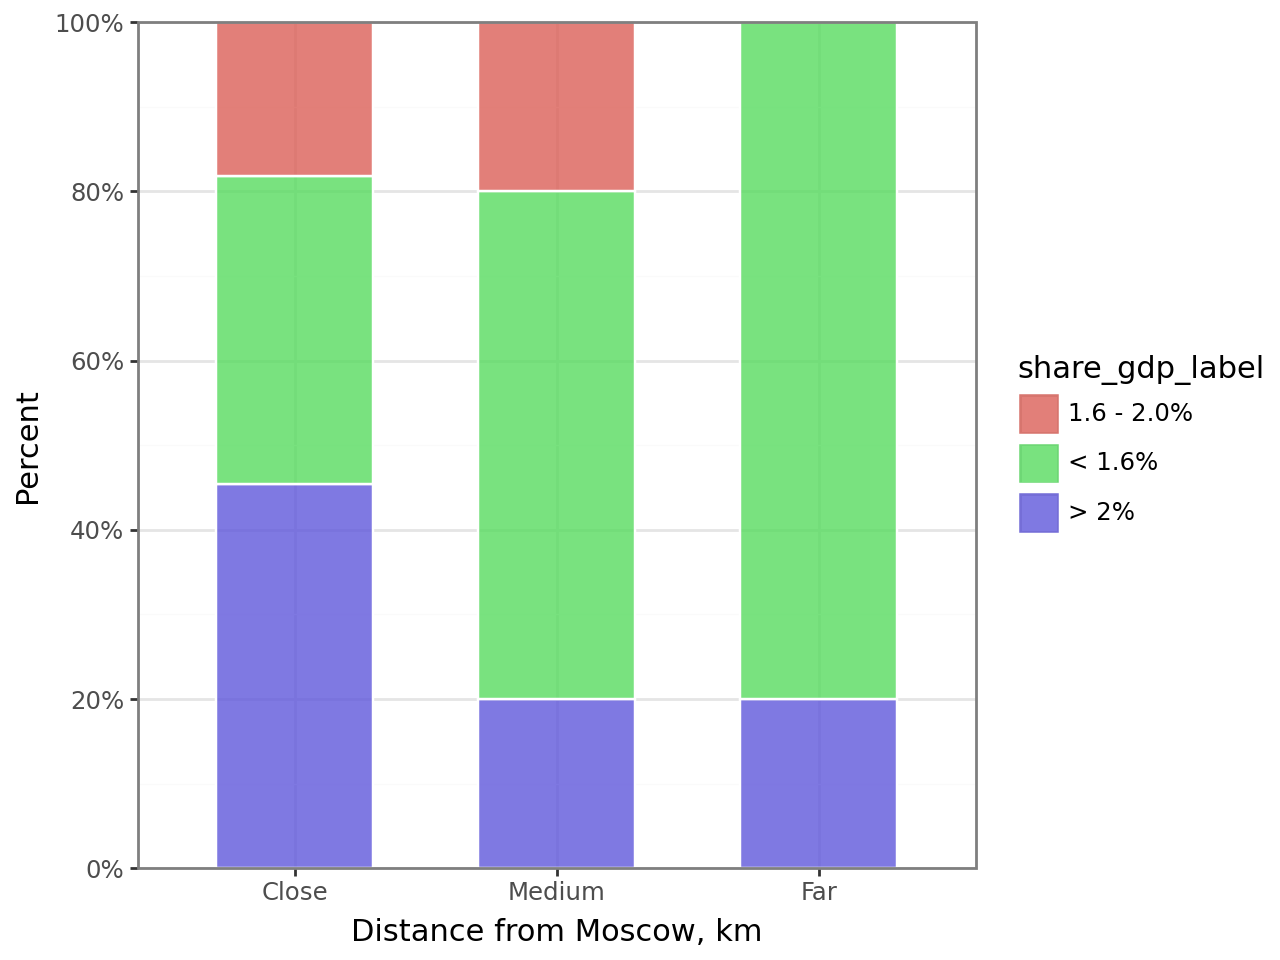

In [ ]:
ggplot(df_stacked, aes(x="distance_bins", y="percent", fill="share_gdp_label")) + geom_bar(
    stat="identity", position="fill", width=0.6, color="white", size=0.5, alpha=0.8
) + scale_y_continuous( 
    expand=(0, 0), limits=(0, 1), breaks=np.arange(0, 1.1, 0.2), labels=percent_format()
) + labs(
    x="Distance from Moscow, km", y="Percent"
) + theme_bw() + theme(
    legend_position="right"
) + scale_x_discrete(limits=[1, 2, 3],
                     labels=["Close", "Medium", "Far"]
)

Initially, we can observe a pattern here. The closer the cities are to Moscow, the higher the `share_GDP` seems to be. It is remarkable how values for > 2% more than double.

# Plotting bin scatters
We can now use our binned values and visualize the correlations using scatterplots. Because we have already binned our values, we can visualize them straight away.

In [ ]:
eur_df_2023_no_ukr.columns

Index(['country', 'year', 'military_expenditures_usd_2022',
       'military_expenditures_current_usd', 'share_GDP', 'share_govt',
       'capital_city', 'latitude', 'longitude', 'moscow_lat', 'moscow_long',
       'distance_km', 'distance_mi', 'distance_bins', 'distance_km_category',
       'share_gdp_bins', 'share_gdp_label'],
      dtype='object')

In [ ]:
eur_df_2023_no_ukr.filter(
    ["distance_km", "distance_bins"]).groupby("distance_bins").agg(
        ["min", "max", "mean", "median", "std", "size"]
    )

distance_km                                                     \
                       min          max         mean       median         std   
distance_bins                                                                   
1                 0.000000  1804.240314  1329.271897  1569.586800  475.263654   
2              1871.837413  2494.330387  2102.042112  2061.505081  202.157578   
3              2508.674067  3915.117069  3135.087753  3067.249290  518.244730   

                    
              size  
distance_bins       
1               22  
2               15  
3                6

In [ ]:
# Recode distance bins
eur_df_2023_no_ukr["distance_bins_recode"] = eur_df_2023_no_ukr["distance_bins"].replace(1, 900).replace(2, 2200).replace(3, 3200)
eur_df_2023_no_ukr["distance_bins_recode"]

0     2200
1      900
2      900
3     2200
4      900
5     2200
6     2200
7      900
8     2200
9      900
10     900
11     900
12     900
13    2200
14     900
15     900
16    2200
17     900
18    3200
19    3200
20    2200
21    2200
22     900
23     900
24    2200
25    3200
26     900
27    2200
28    2200
29    2200
30     900
31     900
32    3200
33     900
34     900
35     900
36     900
37    2200
38    3200
39     900
40    2200
41     900
42    3200
Name: distance_bins_recode, dtype: int64

In [ ]:
eur_df_2023_no_ukr.filter(["distance_km","distance_bins_recode"]).groupby("distance_bins_recode").agg(
    ["min", "max", "mean", "median", "std", "size"]
)

distance_km                                         \
                              min          max         mean       median   
distance_bins_recode                                                       
900                      0.000000  1804.240314  1329.271897  1569.586800   
2200                  1871.837413  2494.330387  2102.042112  2061.505081   
3200                  2508.674067  3915.117069  3135.087753  3067.249290   

                                       
                             std size  
distance_bins_recode                   
900                   475.263654   22  
2200                  202.157578   15  
3200                  518.244730    6

We can now get the mean value of `share_GDP` for each distance bin.

In [ ]:
share_gdp_agg = eur_df_2023_no_ukr.groupby("distance_bins_recode").agg(mean_gdp_expenditure=("share_GDP", "mean")).reset_index()
share_gdp_agg

,distance_bins_recode,mean_gdp_expenditure
0,900,0.022876
1,2200,0.017303
2,3200,0.012137


Nice! We are getting there. Let's plot this result and see what we get.

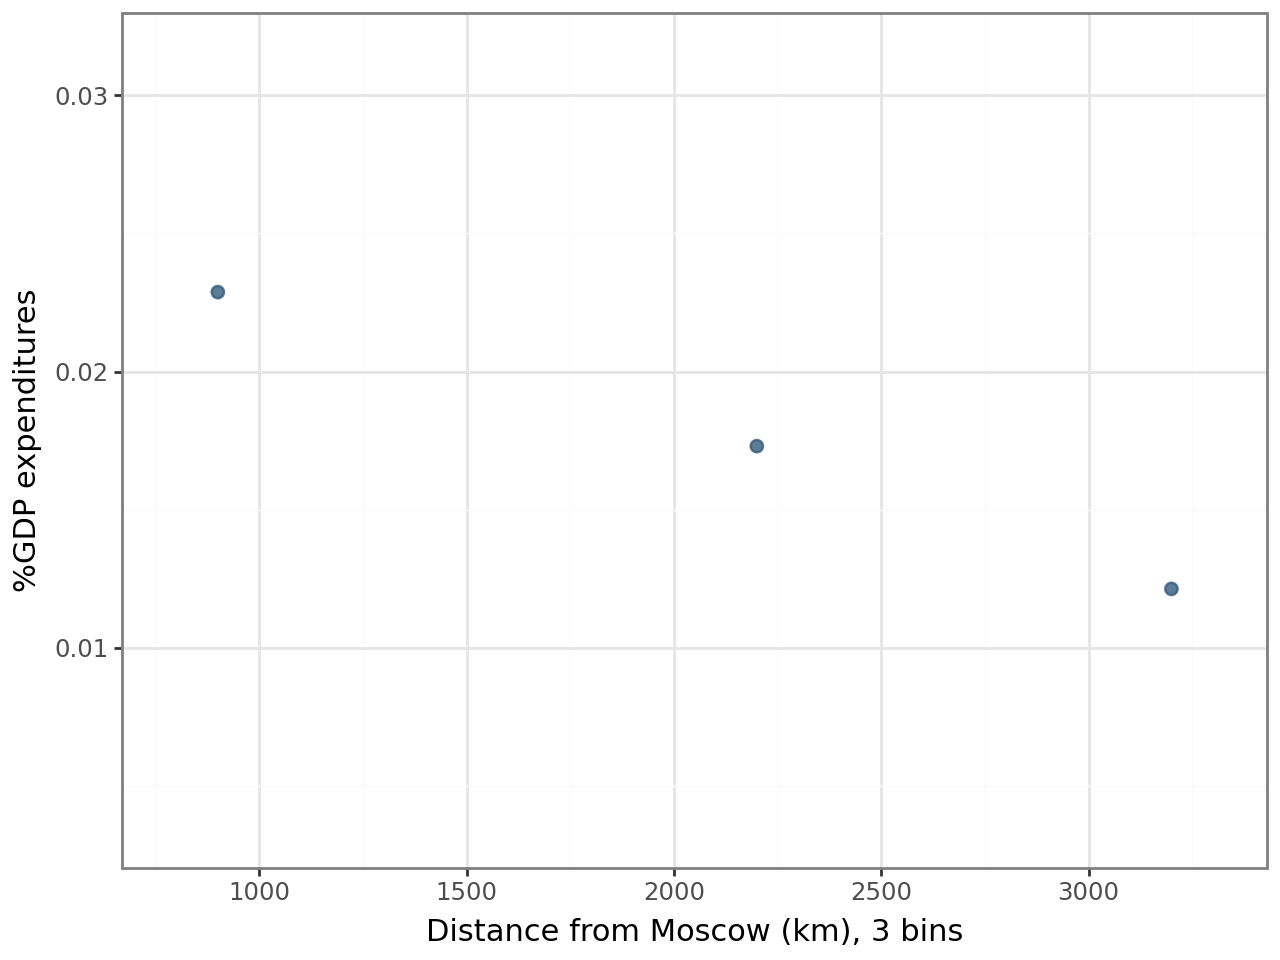

In [ ]:
ggplot(share_gdp_agg, aes(x="distance_bins_recode", y="mean_gdp_expenditure")) + geom_point(
    size=2, alpha=0.8, color="#355C7D", na_rm=True
) + scale_y_continuous(
    expand=(0.01, 0.01)
) + scale_x_continuous(
    expand=(0.1, 1)
) + labs(
    x="Distance from Moscow (km), 3 bins", y="%GDP expenditures"
) + theme_bw()

As we can observe, there is a **negative** correlation between the distance of capital cities and Moscow. For cities far from the Russian capital, the mean value is `1.2%`. For those at a medium distance, the value increases to `1.7%`. Finally, the mean value for cities closer to Moscow is `2.2%`, roughly.

Now, would this trend hold when using a bin scatter of 10 bins? Let's find out. We can use `pd.qcut()`, which discretizes variables into equal-sized buckets.

In [ ]:
eur_df_2023_no_ukr["distance_10_bins"] = pd.qcut(eur_df_2023_no_ukr["distance_km"], 10)

Let's summarize our newly created variable.

In [ ]:
summary_stat = eur_df_2023_no_ukr.filter(["distance_km", "distance_10_bins"]).groupby("distance_10_bins", observed=False).agg(
    ["min", "max", "mean", "median", "std", "size"]
)
summary_stat

distance_km                                         \
                              min          max         mean       median   
distance_10_bins                                                           
(-0.001, 874.959]        0.000000   869.927496   637.109991   793.263248   
(874.959, 1339.301]    895.086147  1231.689760  1107.029773  1150.671592   
(1339.301, 1626.878]  1500.717511  1613.743354  1563.408616  1569.586800   
(1626.878, 1674.216]  1635.635091  1673.075362  1651.781654  1649.208081   
(1674.216, 1804.24]   1674.501261  1804.240314  1753.910322  1779.443902   
(1804.24, 1927.585]   1871.837413  1926.380663  1894.868327  1890.627616   
(1927.585, 2098.851]  1932.401811  2061.505081  1979.044453  1961.135460   
(2098.851, 2281.25]   2154.869717  2260.638611  2216.095588  2224.437012   
(2281.25, 2744.968]   2294.991494  2508.674067  2419.818068  2437.803356   
(2744.968, 3915.117]  2804.041794  3915.117069  3260.370490  3317.465664   

                                       
                             std size  
distance_10_bins                       
(-0.001, 874.959]     363.738125    5  
(874.959, 1339.301]   146.399536    4  
(1339.301, 1626.878]   46.771790    4  
(1626.878, 1674.216]   15.571793    4  
(1674.216, 1804.24]    56.236182    5  
(1804.24, 1927.585]    25.795917    4  
(1927.585, 2098.851]   59.884657    4  
(2098.851, 2281.25]    44.985607    4  
(2281.25, 2744.968]   100.854043    4  
(2744.968, 3915.117]  466.908737    5

Let's now get the midpoint of each bin by replacing the interval with the mean of each interval.

In [ ]:
# Recoding
eur_df_2023_no_ukr["distance_10_bins"] = eur_df_2023_no_ukr["distance_10_bins"].cat.rename_categories(
    summary_stat["distance_km"]["mean"].to_dict()
)

In [ ]:
eur_df_2023_no_ukr.filter(["distance_km", "distance_10_bins"]).groupby("distance_10_bins", observed=True).agg(
    ["min", "max", "mean", "median", "std", "size"],
)

distance_km                                         \
                          min          max         mean       median   
distance_10_bins                                                       
637.109991           0.000000   869.927496   637.109991   793.263248   
1107.029773        895.086147  1231.689760  1107.029773  1150.671592   
1563.408616       1500.717511  1613.743354  1563.408616  1569.586800   
1651.781654       1635.635091  1673.075362  1651.781654  1649.208081   
1753.910322       1674.501261  1804.240314  1753.910322  1779.443902   
1894.868327       1871.837413  1926.380663  1894.868327  1890.627616   
1979.044453       1932.401811  2061.505081  1979.044453  1961.135460   
2216.095588       2154.869717  2260.638611  2216.095588  2224.437012   
2419.818068       2294.991494  2508.674067  2419.818068  2437.803356   
3260.370490       2804.041794  3915.117069  3260.370490  3317.465664   

                                   
                         std size  
distance_10_bins                   
637.109991        363.738125    5  
1107.029773       146.399536    4  
1563.408616        46.771790    4  
1651.781654        15.571793    4  
1753.910322        56.236182    5  
1894.868327        25.795917    4  
1979.044453        59.884657    4  
2216.095588        44.985607    4  
2419.818068       100.854043    4  
3260.370490       466.908737    5

In [ ]:
# Return variables by mean
df_mean_10_bins = eur_df_2023_no_ukr.groupby("distance_10_bins", observed=False).agg(share_gdp_10bins=("share_GDP", "mean")).reset_index()
df_mean_10_bins["share_gdp_10bins_label"] = (df_mean_10_bins["share_gdp_10bins"]*100).round(1)
df_mean_10_bins

,distance_10_bins,share_gdp_10bins,share_gdp_10bins_label
0,637.109991,0.031024,3.1
1,1107.029773,0.020686,2.1
2,1563.408616,0.018036,1.8
3,1651.781654,0.017073,1.7
4,1753.910322,0.024997,2.5
5,1894.868327,0.013854,1.4
6,1979.044453,0.023292,2.3
7,2216.095588,0.016827,1.7
8,2419.818068,0.016574,1.7
9,3260.370490,0.009510,1.0


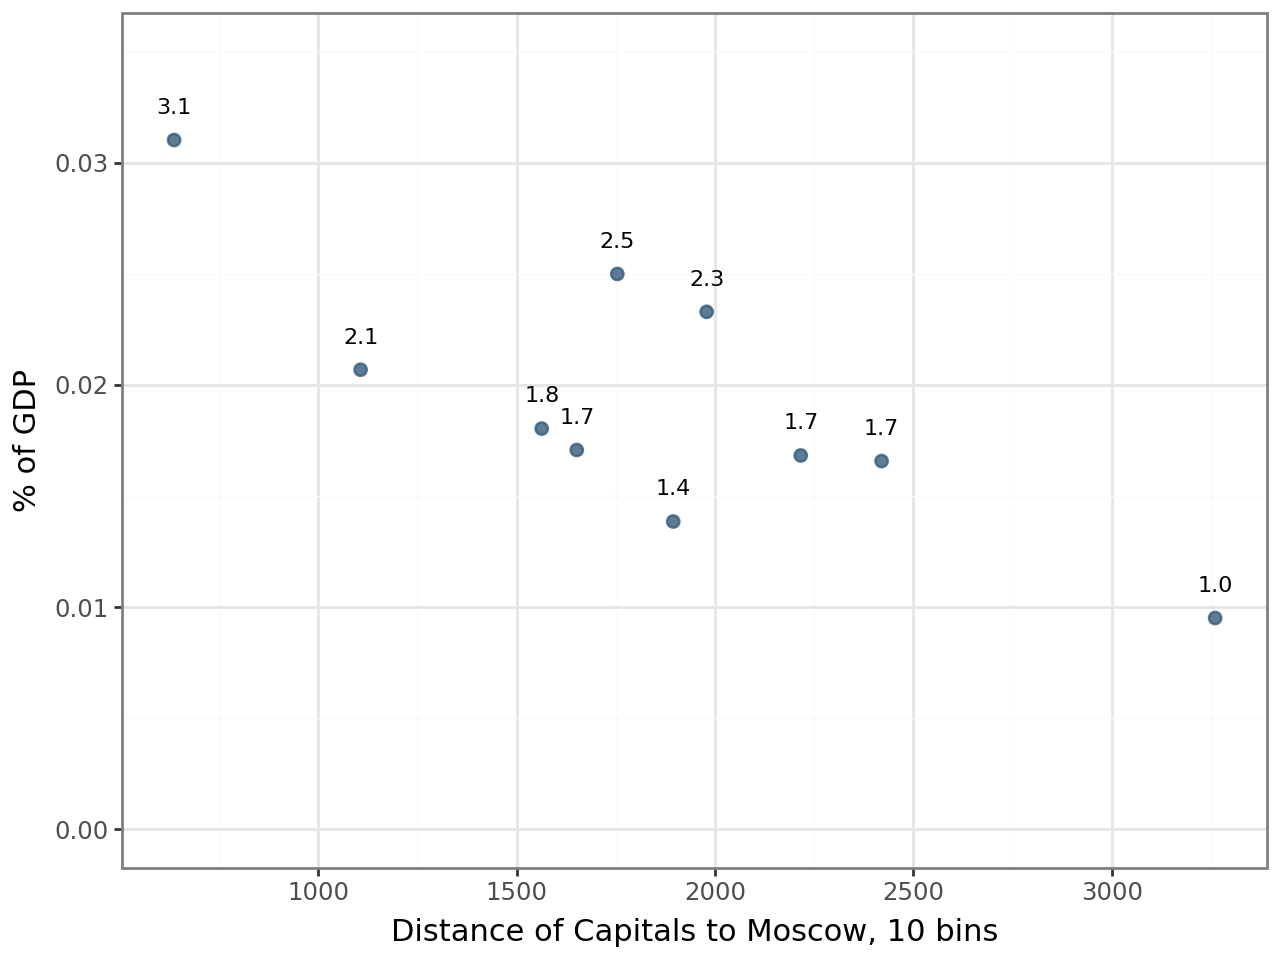

In [ ]:
(
    ggplot(df_mean_10_bins, aes(x="distance_10_bins", y="share_gdp_10bins"))
    + geom_point(size=2, color="#355C7D", alpha=0.8, na_rm=True)
    + geom_text(aes(label="share_gdp_10bins_label"), va="bottom", nudge_y=0.001, size=8)
    + scale_x_continuous()
    + scale_y_continuous(limits=(0, 0.035))
    + labs(x="Distance of Capitals to Moscow, 10 bins", y="% of GDP")
    + theme_bw()
)

By binning our distance category in a larger number, we can clearly see the pattern. 